# Experiment 4: Implementing a Generative Adversarial Network (GAN) for Image Generation

**Aim:** Implement a Deep Convolutional GAN (DCGAN) in TensorFlow/Keras that learns to generate handwritten digits
from random noise, train it with a custom adversarial training loop, and analyse the generated images.

In [1]:
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(7)
LATENT, BATCH, EPOCHS = 100, 128, 15
print("TensorFlow", tf.__version__, "| latent dim", LATENT, "| batch", BATCH, "| epochs", EPOCHS)

I0000 00:00:1792688951.463122    2823 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792688952.676637    2823 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | latent dim 100 | batch 128 | epochs 15


## 1. Data: MNIST scaled to [-1, 1]

In [2]:
(x_train, _), _ = keras.datasets.mnist.load_data()
x_train = ((x_train.astype("float32") - 127.5) / 127.5)[..., None]
ds = tf.data.Dataset.from_tensor_slices(x_train).shuffle(60000, seed=0).batch(BATCH, drop_remainder=True).prefetch(2)
print("training images:", x_train.shape, "range [%.1f, %.1f]" % (x_train.min(), x_train.max()))
print("steps per epoch:", len(ds))

training images: (60000, 28, 28, 1) range [-1.0, 1.0]
steps per epoch: 468


## 2. Generator and Discriminator
The **generator** maps a noise vector $z\in\mathbb{R}^{100}$ to a $28\times28$ image using transposed convolutions.
The **discriminator** is a CNN classifier that outputs the logit "real vs. fake".

In [3]:
def make_generator():
    return keras.Sequential([
        layers.Input((LATENT,)),
        layers.Dense(7 * 7 * 128, use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 128)),
        layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),   # 14x14
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(32, 5, strides=2, padding="same", use_bias=False),   # 28x28
        layers.BatchNormalization(), layers.LeakyReLU(0.2),
        layers.Conv2D(1, 5, padding="same", activation="tanh"),
    ], name="generator")

def make_discriminator():
    return keras.Sequential([
        layers.Input((28, 28, 1)),
        layers.Conv2D(32, 5, strides=2, padding="same"), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Conv2D(64, 5, strides=2, padding="same"), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Flatten(), layers.Dense(1),
    ], name="discriminator")

G, D = make_generator(), make_discriminator()
G.summary(print_fn=print); D.summary(print_fn=print)
z = tf.random.normal((1, LATENT))
print("\nuntrained G(z) shape:", G(z, training=False).shape, "| D(G(z)) logit:", float(D(G(z, training=False))[0, 0]))

Model: "generator"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)   

Model: "discriminator"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼──────────────────


untrained G(z) shape: (1, 28, 28, 1) | D(G(z)) logit: -0.0010288275079801679


## 3. Losses and the adversarial training step
$$\min_G\max_D\; \mathbb{E}_{x}[\log D(x)] + \mathbb{E}_{z}[\log(1-D(G(z)))]$$
The discriminator is trained to label real images 1 and fakes 0; the generator uses the non-saturating loss
(make the discriminator label its fakes as real). One-sided label smoothing (0.9) stabilises training.

In [4]:
bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def train_step(real):
    z = tf.random.normal((tf.shape(real)[0], LATENT))
    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = G(z, training=True)
        real_logit, fake_logit = D(real, training=True), D(fake, training=True)
        d_loss = bce(tf.ones_like(real_logit) * 0.9, real_logit) + bce(tf.zeros_like(fake_logit), fake_logit)
        g_loss = bce(tf.ones_like(fake_logit), fake_logit)
    g_opt.apply_gradients(zip(gt.gradient(g_loss, G.trainable_variables), G.trainable_variables))
    d_opt.apply_gradients(zip(dt.gradient(d_loss, D.trainable_variables), D.trainable_variables))
    d_acc = 0.5 * (tf.reduce_mean(tf.cast(real_logit > 0, tf.float32)) + tf.reduce_mean(tf.cast(fake_logit < 0, tf.float32)))
    return g_loss, d_loss, d_acc
print("train_step compiled with tf.function")

train_step compiled with tf.function


## 4. Training
A fixed noise batch is used after every epoch so that we can watch the *same* latent codes improve over time.

In [5]:
fixed_z = tf.random.normal((64, LATENT), seed=123)
snapshots, history = {}, []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    gl, dl, da = [], [], []
    for batch in ds:
        g, d, a = train_step(batch)
        gl.append(float(g)); dl.append(float(d)); da.append(float(a))
    history.append((np.mean(gl), np.mean(dl), np.mean(da)))
    if epoch in (1, 2, 3, 5, 8, 12, EPOCHS):
        snapshots[epoch] = G(fixed_z, training=False).numpy()
    print(f"epoch {epoch:2d}/{EPOCHS}  g_loss {history[-1][0]:.3f}  d_loss {history[-1][1]:.3f}  "
          f"d_acc {history[-1][2]:.2f}  ({time.time() - t0:.0f}s)")

epoch  1/15  g_loss 0.778  d_loss 1.371  d_acc 0.53  (105s)


epoch  2/15  g_loss 0.834  d_loss 1.342  d_acc 0.58  (259s)


epoch  3/15  g_loss 0.854  d_loss 1.324  d_acc 0.60  (420s)


epoch  4/15  g_loss 0.837  d_loss 1.349  d_acc 0.57  (587s)


epoch  5/15  g_loss 0.831  d_loss 1.353  d_acc 0.56  (789s)


epoch  6/15  g_loss 0.835  d_loss 1.351  d_acc 0.57  (948s)


... (5 outputs left out)

epoch 12/15  g_loss 0.844  d_loss 1.349  d_acc 0.57  (1955s)


epoch 13/15  g_loss 0.839  d_loss 1.350  d_acc 0.56  (2057s)


epoch 14/15  g_loss 0.843  d_loss 1.350  d_acc 0.57  (2158s)


epoch 15/15  g_loss 0.840  d_loss 1.350  d_acc 0.56  (2300s)


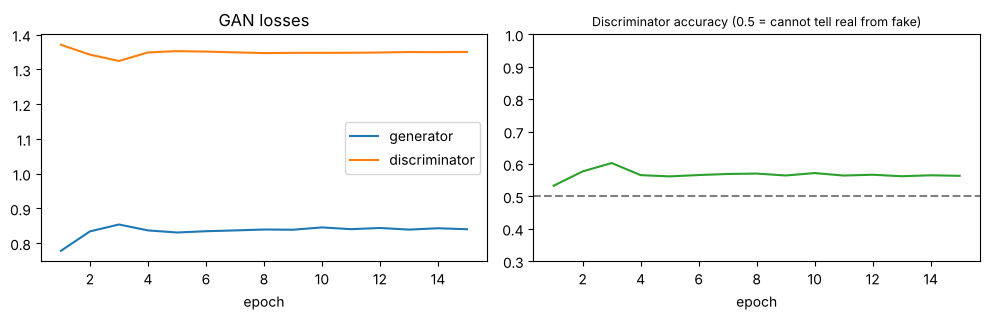

In [6]:
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(range(1, EPOCHS + 1), h[:, 0], label="generator"); ax[0].plot(range(1, EPOCHS + 1), h[:, 1], label="discriminator")
ax[0].set(title="GAN losses", xlabel="epoch"); ax[0].legend()
ax[1].plot(range(1, EPOCHS + 1), h[:, 2], color="tab:green"); ax[1].axhline(0.5, ls="--", c="gray")
ax[1].set(title="Discriminator accuracy (0.5 = cannot tell real from fake)", xlabel="epoch", ylim=(0.3, 1))
ax[1].title.set_fontsize(9)
plt.tight_layout(); plt.show()

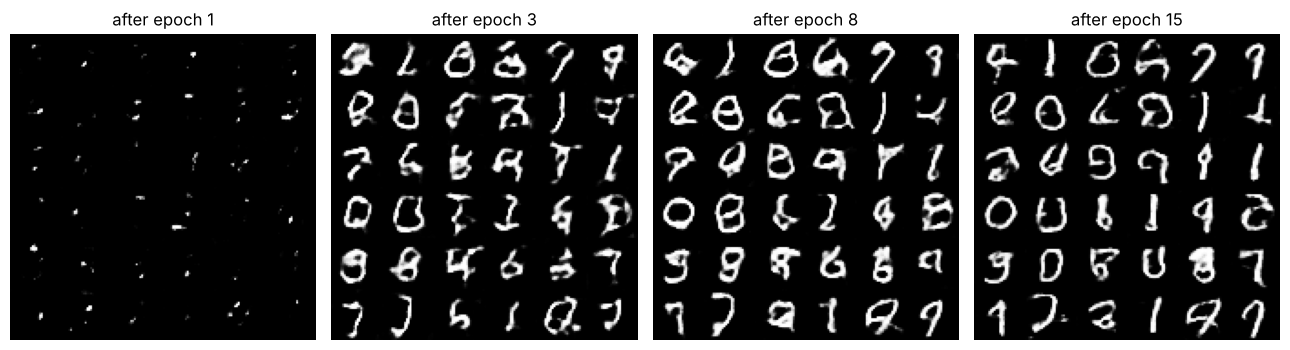

In [7]:
def grid(imgs, n=8):
    imgs = (imgs[: n * n, ..., 0] + 1) / 2
    return np.concatenate([np.concatenate(imgs[r * n:(r + 1) * n], axis=1) for r in range(n)], axis=0)
eps = sorted(snapshots)[::1]
sel = [eps[0], eps[2], eps[4], eps[-1]]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for a, e in zip(axes, sel):
    a.imshow(grid(snapshots[e], 6), cmap="gray"); a.set_title(f"after epoch {e}"); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Evaluating the trained generator

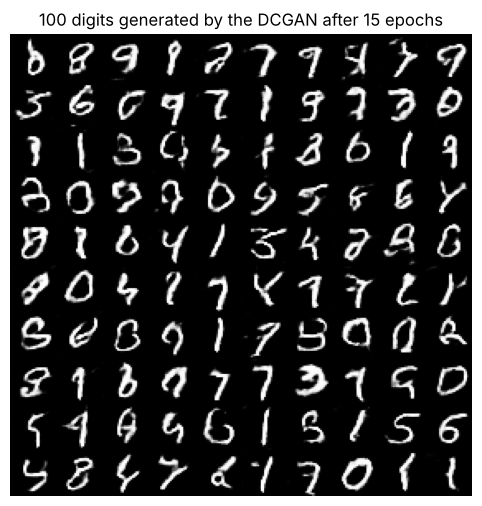

In [8]:
final = G(tf.random.normal((100, LATENT), seed=2024), training=False).numpy()
plt.figure(figsize=(6, 6)); plt.imshow(grid(final, 10), cmap="gray"); plt.axis("off")
plt.title(f"100 digits generated by the DCGAN after {EPOCHS} epochs"); plt.show()

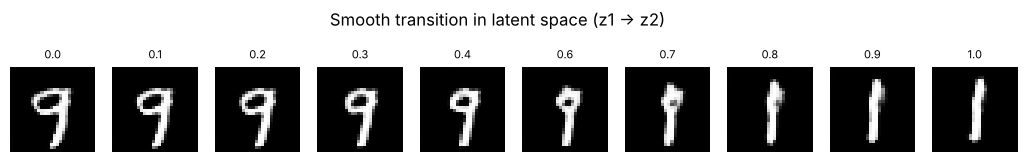

In [9]:
z1, z2 = tf.random.normal((1, LATENT), seed=11), tf.random.normal((1, LATENT), seed=12)
alphas = np.linspace(0, 1, 10)
zs = tf.concat([(1 - a) * z1 + a * z2 for a in alphas], axis=0)
interp = (G(zs, training=False).numpy()[..., 0] + 1) / 2
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for a, im, al in zip(axes, interp, alphas):
    a.imshow(im, cmap="gray"); a.set_title(f"{al:.1f}", fontsize=8); a.axis("off")
plt.suptitle("Smooth transition in latent space (z1 -> z2)", y=1.05); plt.show()

In [10]:
(xc, yc), (xt, yt) = keras.datasets.mnist.load_data()
clf = keras.Sequential([layers.Input((28, 28, 1)), layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
                        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(), layers.Flatten(),
                        layers.Dense(10, activation="softmax")])
clf.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
clf.fit((xc / 255.0)[..., None], yc, epochs=3, batch_size=128, verbose=0)
gen = G(tf.random.normal((2000, LATENT), seed=5), training=False).numpy()
p = clf.predict((gen + 1) / 2, verbose=0)
print("Classifier accuracy on real test digits: %.4f" % clf.evaluate((xt / 255.0)[..., None], yt, verbose=0)[1])
print("Mean max-class confidence on generated digits: %.3f" % p.max(1).mean())
print("Share of generated digits classified with p>0.9: %.1f%%" % (100 * (p.max(1) > 0.9).mean()))
print("Class histogram of generated digits (mode-collapse check):", np.bincount(p.argmax(1), minlength=10).tolist())

Classifier accuracy on real test digits: 0.9787
Mean max-class confidence on generated digits: 0.863
Share of generated digits classified with p>0.9: 60.3%
Class histogram of generated digits (mode-collapse check): [222, 237, 185, 256, 205, 155, 126, 233, 155, 226]
